# AR failure prediction: ML model vs Health Index (Phase 2)

This notebook trains a machine-learning model that answers one question for every NOJA auto recloser (AR):

> **Will this recloser fail in the next 30 days?**

It then compares the model with the mathematical **Health Index (HI)** from Phase 1, both per 15-minute row and as a **daily average per recloser**.

**Where to run it:** **Google Colab** (free, in the browser: colab.research.google.com → File → Upload notebook) or **Jupyter** on your PC.
NotebookLM cannot run code, but you can add this notebook's results to NotebookLM afterwards to ask questions about them.

**Input file:** `ar_ml_dataset.csv.gz` from `D:\AR Preventive Analyze\output\ml\` (made by `python main.py export-dataset`).

**Steps**
1. Load the data (one row per recloser per hour)
2. Build the model inputs (V1–V42 plus 7-day trends)
3. Split by time: train on the past, test on later months
4. Train the model
5. Test it and compare it with the HI
6. Daily average: HI vs ML per recloser per day
7. Save the model for real-time use

Run the cells from top to bottom (Colab: *Runtime → Run all*). The whole notebook takes about 3–6 minutes.

In [1]:
import os, time, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import average_precision_score, precision_recall_curve, roc_auc_score

pd.set_option("display.width", 180)
pd.set_option("display.max_columns", 40)
SEED = 42
HORIZON_DAYS = 30            # the question: failure within the next 30 days?
HI_HEALTHY_MIN = 60          # Phase 1 rule: HI >= 60 means healthy
LOCAL_TZ = "Asia/Colombo"

## 1. Load the data

**In Colab:** run the next cell and pick `ar_ml_dataset.csv.gz` when the upload box appears (89 MB, about 1–2 minutes).
For faster loading, copy the file to your Google Drive, run `from google.colab import drive; drive.mount('/content/drive')`, and put it in *MyDrive*.

**On your PC:** keep this notebook in `D:\AR Preventive Analyze\notebooks\`. It finds the file automatically.

In [2]:
DATA_FILE = "ar_ml_dataset.csv.gz"
candidates = [os.environ.get("AR_ML_DATA", ""), DATA_FILE, os.path.join("..", "output", "ml", DATA_FILE),
              os.path.join("output", "ml", DATA_FILE), "/content/" + DATA_FILE, "/content/drive/MyDrive/" + DATA_FILE]
path = next((p for p in candidates if p and os.path.exists(p)), None)
if path is None:
    try:
        from google.colab import files          # running in Google Colab -> ask for the file
        print("Choose ar_ml_dataset.csv.gz (D:\\AR Preventive Analyze\\output\\ml\\)")
        files.upload()
        path = DATA_FILE
    except ImportError:
        raise FileNotFoundError("Put ar_ml_dataset.csv.gz next to this notebook or set DATA_FILE to its path")
print("Using", path)

Using D:/AR Preventive Analyze/output/ml/ar_ml_dataset.csv.gz


In [3]:
# Read in chunks and keep one row per hour (minute == 00): about 500k rows instead of 2.1 million.
t0 = time.time()
parts = []
for chunk in pd.read_csv(path, chunksize=250_000, parse_dates=["ts"], low_memory=False):
    parts.append(chunk[chunk["ts"].dt.minute == 0])
df = pd.concat(parts, ignore_index=True).sort_values(["asset_id", "ts"]).reset_index(drop=True)
for c in ["telemetry_present", "is_healthy", "failed_now", "failure_next_7d", "failure_next_30d",
          "censored_7d", "censored_30d"]:
    df[c] = df[c].astype(str).str.lower().eq("true")
print(f"{len(df):,} hourly rows, {df['asset_id'].nunique()} reclosers, "
      f"{df['ts'].min():%Y-%m-%d} -> {df['ts'].max():%Y-%m-%d} (UTC), loaded in {time.time() - t0:.0f} s")

525,930 hourly rows, 30 reclosers, 2024-10-05 -> 2026-10-06 (UTC), loaded in 33 s


### The failures in the data
Each row says how many days remain until the recloser's next recorded failure. The cell below rebuilds the list of failures from that.

In [4]:
f = df.loc[df["days_to_next_failure"].notna(), ["asset_id", "ts", "days_to_next_failure", "next_failure_component"]].copy()
f["failure_time"] = f["ts"] + pd.to_timedelta(f["days_to_next_failure"], unit="D")
f = f.sort_values(["asset_id", "failure_time"])
new = (f["asset_id"] != f["asset_id"].shift()) | (f["failure_time"].diff() > pd.Timedelta(hours=1))
failures = (f.loc[new, ["asset_id", "failure_time", "next_failure_component"]]
            .rename(columns={"next_failure_component": "component"}).reset_index(drop=True))
failures["failure_time"] = failures["failure_time"].dt.round("min")
print(f"{len(failures)} failures in {failures['asset_id'].nunique()} reclosers")
display(failures["component"].value_counts().rename_axis("component").to_frame("failures"))
print(f"Rows labelled 'fails within 30 days': {df['failure_next_30d'].mean():.1%}")

56 failures in 27 reclosers


,failures
component,
BATTERY,22
MECHANISM,13
CONTROLLER,13
COMMS,8


Rows labelled 'fails within 30 days': 7.4%


## 2. Model inputs (features)

* **V1–V41** as calculated in Phase 1, plus **weather (V42)**, **model** and **comms channel** as yes/no columns.
* **7-day trends** for the key variables: the change over the last 7 days and the 7-day average. Failures usually show up as things *getting worse*, not only as one bad value.
* **Not used as inputs:** the Health Index, its sub-scores (s01–s42) and factor scores (f_*). Otherwise the model would just copy the HI formula. The label columns are not used either, because they are the answers.

In [5]:
V_COLS = [c for c in df.columns if c[0] == "v" and c[1:3].isdigit() and c != "v42_weather"]
TREND_VARS = ["v01_battery_voltage_v", "v03_soh_est_pct", "v06_max_dod_30d_pct", "v07_battery_alarms_30d",
              "v10_minutes_on_battery_30d", "v11_wear_max_pct", "v27_unsuccessful_ops_30d",
              "v28_scada_availability_24h_pct", "v29_comm_failures_24h", "v30_modem_restarts_30d",
              "v31_signal_strength_24h_dbm", "v33_module_faults_30d", "v34_diag_warnings_30d"]
STEPS_7D = 24 * 7                                    # hourly rows in 7 days

g = df.groupby("asset_id", sort=False)
for c in TREND_VARS:
    df[f"{c}_chg7d"] = df[c] - g[c].shift(STEPS_7D)
    df[f"{c}_mean7d"] = g[c].transform(lambda s: s.rolling(STEPS_7D, min_periods=1).mean())

CAT_COLS = ["v42_weather", "model", "comms_channel"]
num_cols = ["telemetry_present"] + V_COLS + [f"{c}_{k}" for c in TREND_VARS for k in ("chg7d", "mean7d")]
X_all = pd.get_dummies(df[num_cols + CAT_COLS], columns=CAT_COLS, dtype=float)
X_all["telemetry_present"] = X_all["telemetry_present"].astype(float)
FEATURES = list(X_all.columns)
y_all = df["failure_next_30d"].astype(int)
print(len(FEATURES), "input columns")

76 input columns


## 3. Split by time (never randomly)

Neighbouring rows are almost identical, so a random split would leak answers and look far too good. Instead:

| part | used for |
|---|---|
| **fit** | the oldest data: trains the model |
| **valid** | the 3 months after: chooses the alarm threshold |
| **test** | the newest ~35 %: the honest exam the model never saw |

A **30-day gap** separates the parts, because each label looks 30 days ahead.
Rows marked `censored_30d` (the last 30 days, where the outcome isn't known yet) and `failed_now` (already broken) are left out.

In [6]:
usable = (~df["censored_30d"]) & (~df["failed_now"])
t_first, t_last = df.loc[usable, "ts"].min(), df.loc[usable, "ts"].max()
GAP = pd.Timedelta(days=HORIZON_DAYS)
TEST_START = (t_first + (t_last - t_first) * 0.65).normalize()
VALID_START = TEST_START - GAP - pd.Timedelta(days=90)

fit_mask = usable & (df["ts"] < VALID_START - GAP)
valid_mask = usable & (df["ts"] >= VALID_START) & (df["ts"] < TEST_START - GAP)
test_mask = usable & (df["ts"] >= TEST_START)

def failures_between(lo, hi):
    return failures[(failures["failure_time"] > lo) & (failures["failure_time"] <= hi)]

split = pd.DataFrame({
    "from": [t_first, VALID_START, TEST_START],
    "to": [VALID_START - GAP, TEST_START - GAP, t_last],
    "rows": [fit_mask.sum(), valid_mask.sum(), test_mask.sum()],
    "positive rows": [y_all[fit_mask].mean(), y_all[valid_mask].mean(), y_all[test_mask].mean()],
    "failures": [len(failures_between(t_first, VALID_START)),
                 len(failures_between(VALID_START, TEST_START)),
                 len(failures_between(TEST_START, t_last + GAP))],
}, index=["fit", "valid", "test"])
split["positive rows"] = (split["positive rows"] * 100).round(1).astype(str) + " %"
display(split)

,from,to,rows,positive rows,failures
fit,2024-10-05 19:00:00,2025-08-26 00:00:00,231220,4.8 %,17
valid,2025-09-25 00:00:00,2025-12-24 00:00:00,64168,5.5 %,7
test,2026-01-23 00:00:00,2026-10-05 10:00:00,161218,12.6 %,32


## 4. Train the model

The model is **gradient-boosted decision trees** (`HistGradientBoostingClassifier`).
It handles missing values (e.g. V3 with no battery evidence yet, V36 without RS485) and is a strong default for table data.
`class_weight="balanced"` makes the rare failure rows count as much as the many normal rows.
The **alarm threshold** is the probability that best balances catching failures against false alarms (best F1) on the *valid* months.

In [7]:
PARAMS = dict(learning_rate=0.05, max_iter=300, max_leaf_nodes=31, min_samples_leaf=200,
              l2_regularization=1.0, class_weight="balanced", early_stopping=False, random_state=SEED)
t0 = time.time()
model = HistGradientBoostingClassifier(**PARAMS).fit(X_all[fit_mask], y_all[fit_mask])
print(f"trained on {fit_mask.sum():,} rows in {time.time() - t0:.0f} s")

p_valid = model.predict_proba(X_all[valid_mask])[:, 1]
if y_all[valid_mask].sum() > 0:
    prec, rec, thr = precision_recall_curve(y_all[valid_mask], p_valid)
    f1 = 2 * prec * rec / np.maximum(prec + rec, 1e-9)
    THRESHOLD = float(thr[np.argmax(f1[:-1])])
else:
    THRESHOLD = 0.5
print(f"alarm threshold: probability >= {THRESHOLD:.3f}")

trained on 231,220 rows in 16 s


alarm threshold: probability >= 0.143


## 5. Test: ML model vs Health Index

Both are scored on the **test months**, the same way:

* **ROC-AUC / PR-AUC:** how well the score ranks risky rows above safe ones (1.0 = perfect). PR-AUC is the stricter one for rare events; a random guess scores the share of positive rows.
* **Failures caught:** a failure counts as caught if there was a warning in the 30 days before it.
* **Warning days:** how many days before the failure the first warning came.
* **False-alarm days per AR-month:** days with a warning but no failure within 30 days.

The HI's warning is its own rule: **HI < 60** (not healthy).

In [8]:
test = df.loc[test_mask, ["asset_id", "ts", "health_index", "health_class", "is_healthy", "failure_next_30d"]].copy()
test["p_fail"] = model.predict_proba(X_all[test_mask])[:, 1]
test["ml_warn"] = test["p_fail"] >= THRESHOLD
test["hi_warn"] = test["health_index"] < HI_HEALTHY_MIN
test_fails = failures_between(TEST_START, t_last + GAP)

def event_metrics(frame, warn_col, fails):
    rows = []
    for f in fails.itertuples():
        win = frame[(frame["asset_id"] == f.asset_id) & (frame["ts"] < f.failure_time)
                    & (frame["ts"] > f.failure_time - pd.Timedelta(days=HORIZON_DAYS))]
        hits = win[win[warn_col]]
        lead = (f.failure_time - hits["ts"].min()).total_seconds() / 86400 if len(hits) else np.nan
        rows.append((f.asset_id, f.failure_time, f.component, len(hits) > 0, lead))
    per = pd.DataFrame(rows, columns=["asset_id", "failure_time", "component", "caught", "warning_days"])
    alarms = frame[frame[warn_col] & ~frame["failure_next_30d"]]
    false_days = alarms.assign(day=alarms["ts"].dt.floor("D")).drop_duplicates(["asset_id", "day"]).shape[0]
    ar_months = frame.groupby("asset_id")["ts"].agg(lambda s: (s.max() - s.min()).days / 30.44).sum()
    return per, false_days / max(ar_months, 1e-9)

# "ML or HI": warn when either one warns (each score scaled so 1.0 = its own warning level)
test["any_warn"] = test["ml_warn"] | test["hi_warn"]
any_score = np.maximum(test["p_fail"] / THRESHOLD, (100 - test["health_index"]) / (100 - HI_HEALTHY_MIN))

results, per_failure = {}, {}
for name, score, warn in [("ML model", test["p_fail"], "ml_warn"),
                          ("Health Index (HI < 60)", 100 - test["health_index"], "hi_warn"),
                          ("ML or HI (either warns)", any_score, "any_warn")]:
    per, fa = event_metrics(test, warn, test_fails)
    per_failure[name] = per
    results[name] = {"ROC-AUC": round(roc_auc_score(test["failure_next_30d"], score), 3),
                     "PR-AUC": round(average_precision_score(test["failure_next_30d"], score), 3),
                     "failures caught": f"{int(per['caught'].sum())} / {len(per)}",
                     "median warning days": round(per["warning_days"].median(), 1),
                     "false-alarm days per AR-month": round(fa, 2)}
comparison = pd.DataFrame(results).T
print(f"random-guess PR-AUC = {test['failure_next_30d'].mean():.3f}")
display(comparison)

random-guess PR-AUC = 0.126


,ROC-AUC,PR-AUC,failures caught,median warning days,false-alarm days per AR-month
ML model,0.768,0.557,16 / 32,30.0,0.27
Health Index (HI < 60),0.76,0.364,17 / 32,20.4,0.8
ML or HI (either warns),0.823,0.644,26 / 32,30.0,1.07


In [9]:
by_comp = pd.DataFrame({name: per.groupby("component")["caught"].agg(lambda s: f"{int(s.sum())} / {len(s)}")
                        for name, per in per_failure.items()})
by_comp.index.name = "failures caught, by component"
display(by_comp)

detail = per_failure["ML model"].rename(columns={"caught": "ML caught", "warning_days": "ML warning days"})
detail[["HI caught", "HI warning days"]] = per_failure["Health Index (HI < 60)"][["caught", "warning_days"]]
display(detail.round(1))

,ML model,Health Index (HI < 60),ML or HI (either warns)
"failures caught, by component",,,
BATTERY,12 / 13,5 / 13,12 / 13
COMMS,1 / 4,0 / 4,1 / 4
CONTROLLER,2 / 7,5 / 7,6 / 7
MECHANISM,1 / 8,7 / 8,7 / 8


,asset_id,failure_time,component,ML caught,ML warning days,HI caught,HI warning days
0,AR-002,2026-07-07 11:30:00,BATTERY,True,30.0,True,8.1
1,AR-002,2026-09-16 22:21:00,MECHANISM,False,NaN,False,NaN
2,AR-003,2026-06-11 23:15:00,CONTROLLER,False,NaN,False,NaN
3,AR-004,2026-05-08 01:15:00,MECHANISM,False,NaN,True,30.0
4,AR-004,2026-08-03 22:15:00,BATTERY,True,30.0,False,NaN
5,AR-007,2026-07-18 03:45:00,BATTERY,True,30.0,False,NaN
6,AR-008,2026-01-23 01:45:00,BATTERY,True,0.1,False,NaN
7,AR-008,2026-08-16 13:00:00,BATTERY,False,NaN,False,NaN
8,AR-008,2026-10-01 15:00:00,MECHANISM,False,NaN,True,30.0
9,AR-009,2026-09-13 22:00:00,CONTROLLER,False,NaN,True,4.9


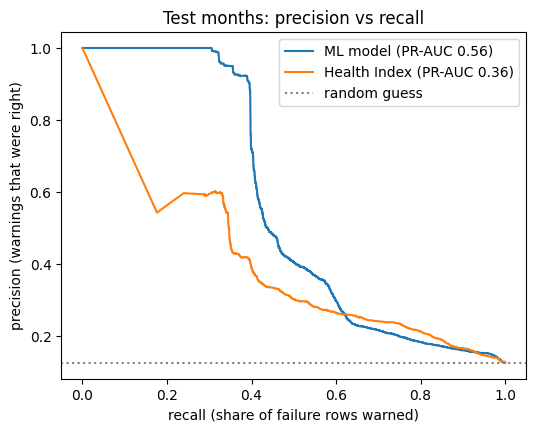

In [10]:
fig, ax = plt.subplots(figsize=(6, 4.5))
for name, score in [("ML model", test["p_fail"]), ("Health Index", 100 - test["health_index"])]:
    p, r, _ = precision_recall_curve(test["failure_next_30d"], score)
    ax.plot(r, p, label=f"{name} (PR-AUC {average_precision_score(test['failure_next_30d'], score):.2f})")
ax.axhline(test["failure_next_30d"].mean(), color="grey", ls=":", label="random guess")
ax.set_xlabel("recall (share of failure rows warned)"); ax.set_ylabel("precision (warnings that were right)")
ax.set_title("Test months: precision vs recall"); ax.legend(); plt.show()

### One recloser over time
HI (blue, left axis) and ML failure probability (red, right axis) for the test-period recloser where ML and HI together caught the most failures. The dashed lines are the two warning levels; the black lines are recorded failures. Gaps are periods when the recloser was broken and waiting for repair.

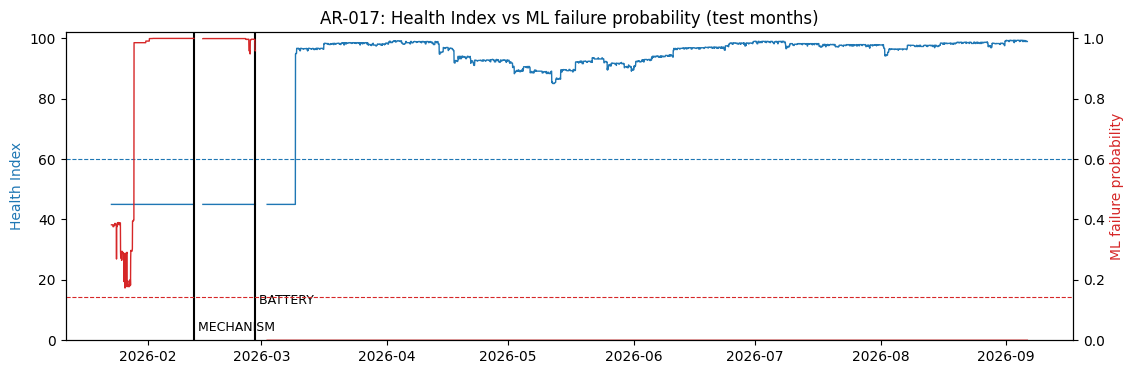

In [11]:
if len(test_fails):
    both = sum(per_failure[k].groupby("asset_id")["caught"].sum() for k in ("ML model", "Health Index (HI < 60)"))
    aid = both.sort_values(kind="stable").index[-1]            # recloser where both models caught the most
    a = (test[test["asset_id"] == aid].set_index("ts")[["health_index", "p_fail"]]
         .resample("1h").asfreq().reset_index())          # NaN rows break the lines at gaps
    fig, ax1 = plt.subplots(figsize=(13, 4))
    ax1.plot(a["ts"], a["health_index"], color="tab:blue", lw=1, label="Health Index")
    ax1.axhline(HI_HEALTHY_MIN, color="tab:blue", ls="--", lw=0.8)
    ax1.set_ylabel("Health Index", color="tab:blue"); ax1.set_ylim(0, 102)
    ax2 = ax1.twinx()
    ax2.plot(a["ts"], a["p_fail"], color="tab:red", lw=1, label="ML probability of failure in 30 d")
    ax2.axhline(THRESHOLD, color="tab:red", ls="--", lw=0.8)
    ax2.set_ylabel("ML failure probability", color="tab:red"); ax2.set_ylim(0, 1.02)
    rows = test_fails[test_fails["asset_id"] == aid][["failure_time", "component"]].itertuples(index=False)
    for k, (ft, comp) in enumerate(rows):
        ax1.axvline(ft, color="black", lw=1.5); ax1.text(ft, 3 + 9 * (k % 2), f" {comp}", fontsize=9)
    ax1.set_title(f"{aid}: Health Index vs ML failure probability (test months)")
    plt.show()

### What the model relies on
Permutation importance shuffles one input at a time and measures how much worse the model gets.

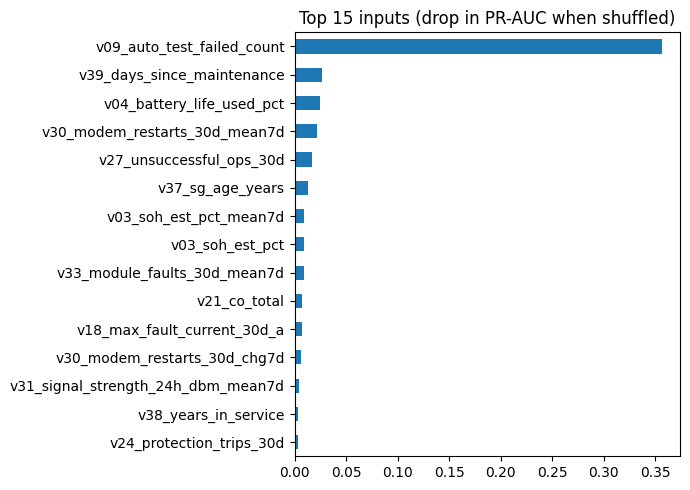

In [12]:
sample = X_all[test_mask].sample(min(40_000, int(test_mask.sum())), random_state=SEED)
pi = permutation_importance(model, sample, y_all.loc[sample.index], scoring="average_precision",
                            n_repeats=3, random_state=SEED, n_jobs=-1)
importance = pd.Series(pi.importances_mean, index=FEATURES).sort_values(ascending=False).head(15)
importance[::-1].plot.barh(figsize=(7, 5), title="Top 15 inputs (drop in PR-AUC when shuffled)")
plt.tight_layout(); plt.show()

## 6. Daily average: HI vs ML for every recloser and day

For each recloser and local day (Asia/Colombo):

* **avg_hi:** the day's average Health Index; **HI healthy** = avg_hi ≥ 60
* **ml_health:** 100 × (1 − average failure probability), shown on a 0–100 scale like the HI
* **ML healthy:** the probability stayed below the alarm threshold all day
* **agree:** HI and ML give the same verdict

In [13]:
d = test.assign(date=test["ts"].dt.tz_localize("UTC").dt.tz_convert(LOCAL_TZ).dt.date)
daily = (d.groupby(["asset_id", "date"])
          .agg(avg_hi=("health_index", "mean"), min_hi=("health_index", "min"),
               avg_p=("p_fail", "mean"), max_p=("p_fail", "max"), fails_within_30d=("failure_next_30d", "max"))
          .reset_index())
daily["ml_health"] = 100 * (1 - daily["avg_p"])
daily["hi_healthy"] = daily["avg_hi"] >= HI_HEALTHY_MIN
daily["ml_healthy"] = daily["max_p"] < THRESHOLD
daily["agree"] = daily["hi_healthy"] == daily["ml_healthy"]

print(f"{len(daily):,} recloser-days; HI and ML agree on {daily['agree'].mean():.1%} of them")
display(pd.crosstab(daily["hi_healthy"].map({True: "HI: healthy", False: "HI: NOT healthy"}),
                    daily["ml_healthy"].map({True: "ML: healthy", False: "ML: NOT healthy"})))
print("Days where they disagree, highest ML risk first:")
display(daily[~daily["agree"]].sort_values("max_p", ascending=False).head(10).round(3))
daily.round(4).to_csv("ar_daily_hi_vs_ml.csv", index=False)
print("saved ar_daily_hi_vs_ml.csv")

6,764 recloser-days; HI and ML agree on 90.4% of them


ml_healthy,ML: NOT healthy,ML: healthy
hi_healthy,,
HI: NOT healthy,87,325
HI: healthy,326,6026


Days where they disagree, highest ML risk first:


,asset_id,date,avg_hi,min_hi,avg_p,max_p,fails_within_30d,ml_health,hi_healthy,ml_healthy,agree
3129,AR-014,2026-08-17,84.954,84.110,1.000,1.0,True,0.001,True,False,False
3128,AR-014,2026-08-16,85.191,84.745,1.000,1.0,True,0.001,True,False,False
3127,AR-014,2026-08-15,85.110,84.680,1.000,1.0,True,0.001,True,False,False
3119,AR-014,2026-08-07,86.637,85.369,0.542,1.0,True,45.832,True,False,False
2169,AR-010,2026-05-29,81.153,80.909,1.000,1.0,True,0.001,True,False,False
2166,AR-010,2026-05-26,81.132,80.908,1.000,1.0,True,0.001,True,False,False
2167,AR-010,2026-05-27,81.211,80.866,1.000,1.0,True,0.001,True,False,False
2165,AR-010,2026-05-25,80.996,80.650,1.000,1.0,True,0.001,True,False,False
2168,AR-010,2026-05-28,81.202,80.871,1.000,1.0,True,0.001,True,False,False
3124,AR-014,2026-08-12,84.622,83.839,1.000,1.0,True,0.001,True,False,False


saved ar_daily_hi_vs_ml.csv


## 7. Save the model for real-time use

The final model is retrained on **all** usable rows with the same settings and alarm threshold, then saved as `ar_failure_model.joblib`.
Every 15 minutes, the real-time step can load it, build the same inputs from the newest `ar_variables_15min` rows (including the 7-day trends), and compare `p_fail >= threshold` with the HI.

In [14]:
final_model = HistGradientBoostingClassifier(**PARAMS).fit(X_all[usable], y_all[usable])
bundle = {"model": final_model, "features": FEATURES, "threshold": THRESHOLD, "trend_vars": TREND_VARS,
          "trend_window_hours": STEPS_7D, "horizon_days": HORIZON_DAYS, "trained_rows": int(usable.sum()),
          "data_until_utc": str(t_last), "created": pd.Timestamp.now().isoformat(timespec="seconds")}
joblib.dump(bundle, "ar_failure_model.joblib")
with open("ar_model_results.json", "w") as fh:
    json.dump({"threshold": THRESHOLD, "test_start_utc": str(TEST_START),
               "comparison": comparison.astype(str).to_dict(orient="index")}, fh, indent=2)
print("saved ar_failure_model.joblib and ar_model_results.json")
try:
    from google.colab import files               # Colab: download the results to your PC
    for fn in ["ar_failure_model.joblib", "ar_daily_hi_vs_ml.csv", "ar_model_results.json"]:
        files.download(fn)
except ImportError:
    print("files are in", os.path.abspath("."))

saved ar_failure_model.joblib and ar_model_results.json
files are in D:\AR Preventive Analyze\notebooks


## Reading the results honestly

* **There are few failures.** One more or one less caught changes the percentages a lot, so treat small differences between ML and HI as noise.
* **The data is simulated** (Phase 1). The model learns the patterns the simulator built in. Before trusting it, test it on real NOJA recloser data.
* **The probabilities are not calibrated.** `class_weight="balanced"` pushes them up, so use them for ranking and with the chosen threshold, not as exact percentages.
* **More failures → better model.** Regenerate with more reclosers (`init-db --reset`, `seed --assets 100`, `backfill`, `export-dataset`) and run this notebook again.